# SQL cross-check with pandas

This notebook independently recomputes headline eligible-sales totals from the locally generated clean CSV. It keeps the CSV preparation pipeline unchanged and checks aggregate results against committed MySQL query outputs. It does not print customer IDs or invoice-level records.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path("data/processed/online_retail_clean.csv")
if not csv_path.exists():
    csv_path = Path("../data/processed/online_retail_clean.csv")
df = pd.read_csv(csv_path, encoding="utf-8-sig", parse_dates=["InvoiceDate"])
print("Columns:", df.columns.tolist())
print("Rows:", f"{len(df):,}")
sales = df[
    (df["is_cancellation"] == 0)
    & (df["is_non_product"] == 0)
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
    & df["InvoiceDate"].notna()
].copy()


Columns: ['source_sheet', 'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'is_cancellation', 'is_guest', 'is_non_product', 'line_revenue']
Rows: 1,044,848


In [2]:
gross_revenue = sales["line_revenue"].sum()
orders = sales["Invoice"].nunique()
customers = sales["Customer ID"].nunique()
cancelled_value = df.loc[
    (df["is_cancellation"] == 1) & (df["is_non_product"] == 0), "line_revenue"
].abs().sum()
cancelled_invoices = df.loc[df["is_cancellation"] == 1, "Invoice"].nunique()
all_invoices = df["Invoice"].nunique()
net_revenue = gross_revenue - cancelled_value
average_order_value = gross_revenue / orders
cancellation_rate = cancelled_invoices / all_invoices
customer_orders = sales.dropna(subset=["Customer ID"]).groupby("Customer ID")["Invoice"].nunique()
repeat_customers = int((customer_orders >= 2).sum())
repeat_customer_rate = repeat_customers / customers

expected = {
    "gross_revenue": 19_700_954.457,
    "cancelled_value": 719_692.940,
    "net_revenue": 18_981_261.517,
    "orders": 39_516,
    "customers": 5_852,
    "average_order_value": 498.5563937899,
    "cancelled_invoices": 8_292,
    "cancellation_rate": 0.1546,
    "repeat_customers": 4_234,
    "repeat_customer_rate": 0.7235,
}
actual = {
    "gross_revenue": gross_revenue,
    "cancelled_value": cancelled_value,
    "net_revenue": net_revenue,
    "orders": orders,
    "customers": customers,
    "average_order_value": average_order_value,
    "cancelled_invoices": cancelled_invoices,
    "cancellation_rate": cancellation_rate,
    "repeat_customers": repeat_customers,
    "repeat_customer_rate": repeat_customer_rate,
}
for key, target in expected.items():
    tolerance = 0.02 if "revenue" in key or key in {"cancelled_value", "average_order_value"} else (0.00005 if "rate" in key else 0.000001)
    assert abs(actual[key] - target) < tolerance, f"{key}: got {actual[key]}, expected {target}"
    print(f"PASS {key}: {actual[key]:,.6f}")
print(f"All {len(expected)} SQL checks passed.")


PASS gross_revenue: 19,700,954.457000
PASS cancelled_value: 719,692.940000
PASS net_revenue: 18,981,261.517000
PASS orders: 39,516.000000
PASS customers: 5,852.000000
PASS average_order_value: 498.556394
PASS cancelled_invoices: 8,292.000000
PASS cancellation_rate: 0.154621
PASS repeat_customers: 4,234.000000
PASS repeat_customer_rate: 0.723513
All 10 SQL checks passed.


## Monthly revenue

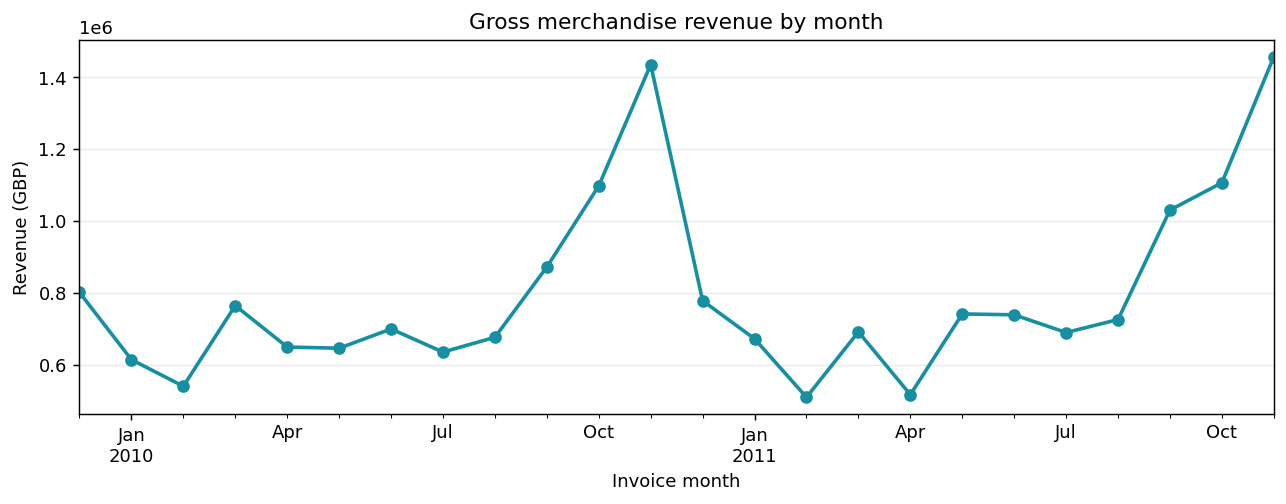

In [3]:
monthly = sales.loc[~((sales["InvoiceDate"].dt.year == 2011) & (sales["InvoiceDate"].dt.month == 12))].copy()
monthly["month"] = monthly["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
monthly_revenue = monthly.groupby("month")["line_revenue"].sum().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
monthly_revenue.plot(ax=ax, color="#168FA3", marker="o", linewidth=2)
ax.set(title="Gross merchandise revenue by month", xlabel="Invoice month", ylabel="Revenue (GBP)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig

The chart groups eligible product sales by invoice month and omits incomplete December 2011. It should reproduce the monthly SQL series for full months.

## Revenue by country

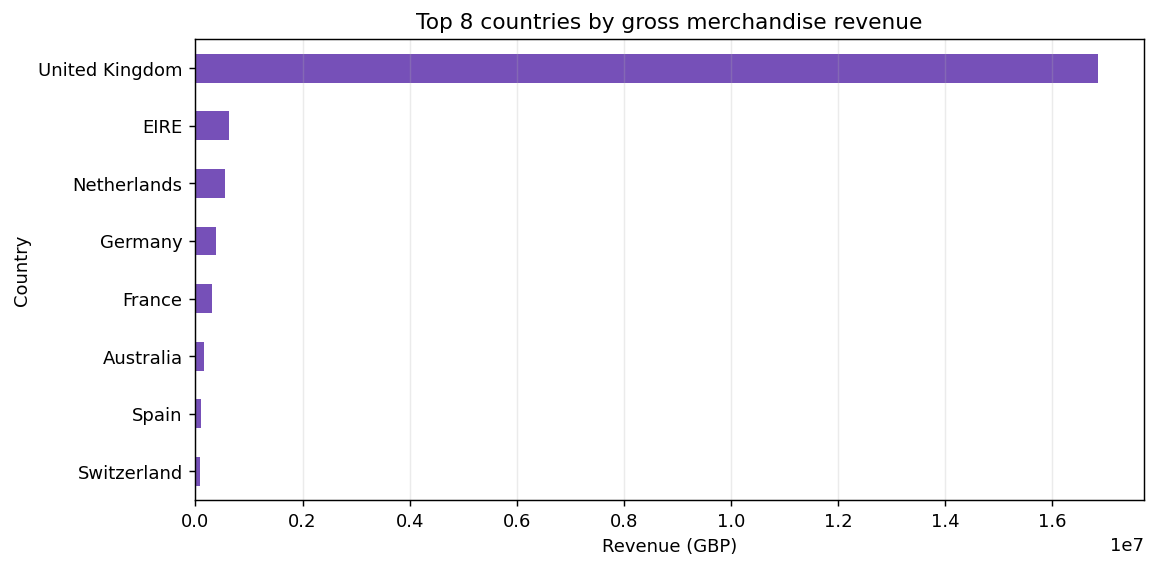

In [4]:
country_revenue = sales.groupby("Country")["line_revenue"].sum().sort_values(ascending=False).head(8).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
country_revenue.plot.barh(ax=ax, color="#7650B8")
ax.set(title="Top 8 countries by gross merchandise revenue", xlabel="Revenue (GBP)", ylabel="Country")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig

The bars show the eight highest gross merchandise revenue totals. Country totals include guest and identified transactions, consistent with the SQL revenue definition.

## Orders by weekday

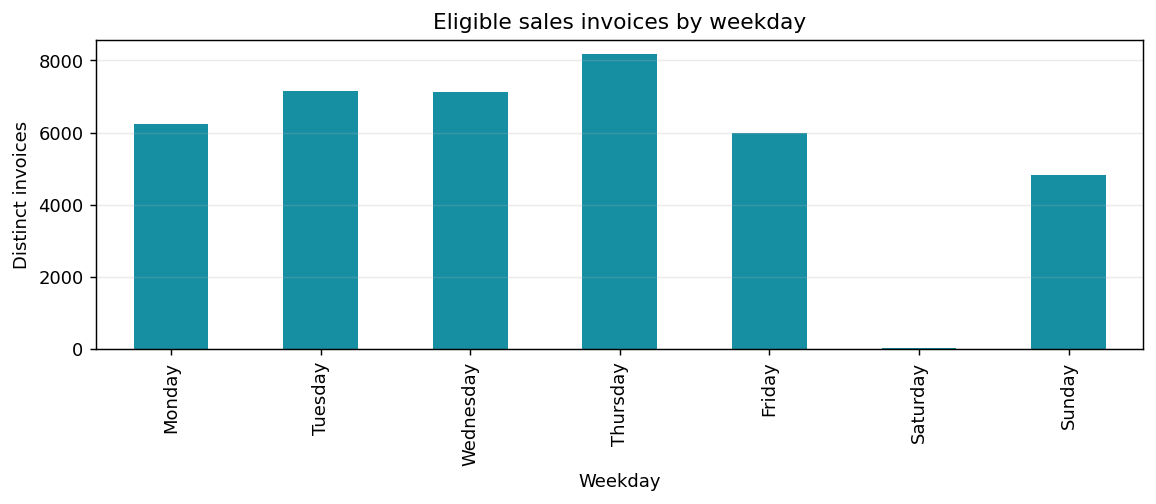

In [5]:
invoice_weekday = sales.drop_duplicates("Invoice").assign(weekday=lambda x: x["InvoiceDate"].dt.day_name())
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_orders = invoice_weekday.groupby("weekday")["Invoice"].nunique().reindex(weekday_order, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4))
weekday_orders.plot.bar(ax=ax, color="#168FA3")
ax.set(title="Eligible sales invoices by weekday", xlabel="Weekday", ylabel="Distinct invoices")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig

The chart counts eligible sales invoices by weekday. It describes this observation window and does not establish an ideal staffing schedule.

## Scope notes

- Revenue checks use non-cancelled, non-product-excluded lines with positive quantity and price and a valid invoice timestamp.
- Registered customers count nonblank customer IDs among eligible sales; guest rows remain in transaction revenue.
- Cancellation value is the absolute merchandise value on cancellation rows. Cancellation rate is cancellation invoices divided by all distinct invoice IDs.
- The notebook checks query 01's totals and query 08's repeat-customer count/rate. DAX parity remains unverified until the PBIX is inspected in Power BI Desktop.